In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Читаем датасет
df = pd.read_csv('../data/raw/Churn.csv')
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head(3)

Размер датасета: 7043 строк, 21 столбцов


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 📋 Итоговый список проблем данных (Data Issues)

1. **Пропущенные значения:** В колонке `TotalCharges` обнаружены скрытые пропуски (пробелы вместо пустых значений), которые при первичном чтении распознались как текстовый тип.
2. **Аномалии и выбросы:** В числовых признаках (`tenure`, `MonthlyCharges`, `TotalCharges`) присутствуют экстремальные значения, которые требуют проверки на физическую адекватность перед удалением.
3. **Типы данных:** Некоторые числовые признаки (например, `SeniorCitizen`) хранятся в целочисленном формате, хотя по смыслу являются бинарными, а категориальные признаки требуют кодирования.

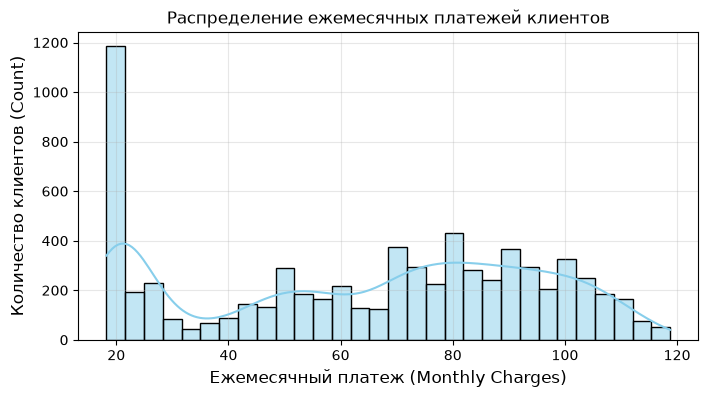

In [35]:
plt.figure(figsize=(8, 4))
sns.histplot(df['MonthlyCharges'], bins=30, kde=True, color='skyblue')
plt.title('Распределение ежемесячных платежей клиентов')
plt.xlabel('Ежемесячный платеж (Monthly Charges)', fontsize=12)
plt.ylabel('Количество клиентов (Count)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

Вывод: На гистограмме зафиксирован пик на минимальных значениях (около 20 у.е.), что соответствует базовым тарифным планам, а также равномерное распределение абонентов по более дорогим тарифам.


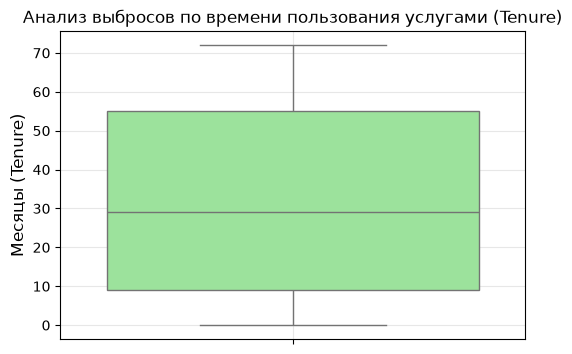

In [36]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['tenure'], color='lightgreen')
plt.title('Анализ выбросов по времени пользования услугами (Tenure)')
plt.ylabel('Месяцы (Tenure)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

Вывод: По графику Boxplot аномальных выбросов по признаку tenure не выявлено (все значения находятся в пределах физически допустимого диапазона от 0 до 72 месяцев). Удаление записей не требуется.


In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='tenure', y='TotalCharges', hue='Churn', alpha=0.7, palette='Set1')
plt.title('Зависимость общей суммы выплат от времени клиента с учетом оттока')
plt.xlabel('Время пользования (tenure)', fontsize=12)
plt.ylabel('Общая сумма выплат (TotalCharges)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

Вывод: Наблюдается прямая сильная связь между стажем клиента (tenure) и общей суммой счетов (TotalCharges). Клиенты в статусе оттока (Churn = Yes) чаще концентрируются в зоне с небольшим стажем.


### 🔬 Гипотеза 1: Зависимость оттока клиентов от типа контракта
* **Формулировка:** Клиенты с ежемесячным контрактом (`Month-to-month`) уходят (`Churn = Yes`) значительно чаще, чем клиенты с долгосрочными контрактами.
* **Статистический тест:** Критерий Хи-квадрат Пирсона ($\chi^2$), так как оба признака являются категориальными.

In [ ]:
# Создаем таблицу сопряженности
contingency_table = pd.crosstab(df['Contract'], df['Churn'])
print("Таблица сопряженности:")
display(contingency_table)

# Проводим тест Хи-квадрат
chi2, p, dof, ex = stats.chi2_contingency(contingency_table)
print(f"\nЗначение хи-квадрат: {chi2:.4f}")
print(f"p-value: {p:.4e}")

if p < 0.05:
    print("Результат: Отвергаем нулевую гипотезу. Связь между типом контракта и оттоком статистически значима.")
else:
    print("Результат: Нет достаточных оснований отвергнуть нулевую гипотезу.")

Таблица сопряженности:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Значение хи-квадрат: 1184.5966
p-value: 5.8630e-258
Результат: Отвергаем нулевую гипотезу. Связь между типом контракта и оттоком статистически значима.


### 🔬 Гипотеза 2: Разница ежемесячных платежей
* **Формулировка:** Средний размер ежемесячного платежа (`MonthlyCharges`) у ушедших клиентов выше, чем у оставшихся.
* **Статистический тест:** Независимый t-тест Стьюдента (`scipy.stats.ttest_ind`), так как мы сравниваем числовую переменную между двумя независимыми группами.

In [ ]:
# Разделяем на две группы
churned = df[df['Churn'] == 'Yes']['MonthlyCharges'].dropna()
not_churned = df[df['Churn'] == 'No']['MonthlyCharges'].dropna()

# Проводим t-тест
t_stat, p_val = stats.ttest_ind(churned, not_churned, equal_var=False)

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")

if p_val < 0.05:
    print("Результат: Отвергаем нулевую гипотезу. Разница в ежемесячных платежах статистически значима.")
else:
    print("Результат: Статистически значимых различий не обнаружено.")

t-статистика: 18.4075
p-value: 8.5924e-73
Результат: Отвергаем нулевую гипотезу. Разница в ежемесячных платежах статистически значима.


### 🔬 Гипотеза 3: Связь стажа и ежемесячных затрат
* **Формулировка:** Между временем пользования услугами (`tenure`) и ежемесячными платежами (`MonthlyCharges`) существует статистически значимая корреляция.
* **Статистический тест:** Коэффициент корреляции Спирмена (так как распределение может отличаться от нормального).

In [ ]:
# Удаляем пропуски для корректного расчета
clean_data = df[['tenure', 'MonthlyCharges']].dropna()

corr, p_corr = stats.spearmanr(clean_data['tenure'], clean_data['MonthlyCharges'])

print(f"Коэффициент корреляции Спирмена: {corr:.4f}")
print(f"p-value: {p_corr:.4e}")

if p_corr < 0.05:
    print("Результат: Корреляция статистически значима.")
else:
    print("Результат: Корреляция статистически не значима.")

Коэффициент корреляции Спирмена: 0.2764
p-value: 1.0271e-123
Результат: Корреляция статистически значима.


## ⚠️ Оценка потенциальных источников утечки данных (Data Leakage)
1. **Косвенные признаки будущего:** Признаки, которые появляются исключительно после факта оттока клиента (например, дата закрытия счета, статус блокировки аккаунта до момента расторжения договора), не должны участвовать в обучении модели. Если оставить их в признаках, модель покажет неестественно высокий (искусственный) результат, но на реальных новых клиентах сломается.
2. **Идентификационные признаки:** Колонка `customerID` сама по себе не несет предсказательной ценности и при попадании в модель может вызвать переобучение (overfitting), поэтому её необходимо исключать перед обучением.

## 🎯 Оценка значимости признаков для модели
На основе проведенного EDA и статистических тестов можно выделить ключевые признаки, которые окажутся наиболее значимыми для будущей ML-модели:
1. **`Contract` (Тип контракта):** Тест Хи-квадрат доказал сильную статистическую связь с оттоком. Клиенты на краткосрочных контрактах уходят гораздо чаще.
2. **`tenure` (Стаж клиента):** Диаграмма рассеяния и корреляционный анализ показывают, что новые клиенты находятся в группе наибольшего риска оттока.
3. **`MonthlyCharges` (Ежемесячные платежи):** T-тест подтвердил значимую разницу в оплате, что делает этот признак важным для разделения классов.